## PID-Regler

Um der Straße folgen zu können muss der Roboter zunächst mithilfe von seinem Kamera Bild herausfinden wo die Spur Eigentlich ist. Wenn der Roboter weiß wo die Spur ist muss er nun seine Motoren so ansteuern, dass er der Spur folgt. Das Problem dabei ist, dass der Roboter nicht perfekt gerade aus fährt. Früher oder später kommt er von der Spur ab und muss gegensteuern um nicht die Fahrspur zu verlassen. Er darf aber auch nicht zu stark lenken, sonst kommt er auf der anderen Seite von der Spur ab. 

Um den Roboter kontinuierlich in der Spurzuhalten verwenden wir einen sogennanten PID-Regler. Ein PID-Regler besteht aus 3 Komponenten. Die erste Komponente ist der p-Anteil. Er beschreibt wie stark der Roboter auf einen Aktuellen Fehler reagiert. Der P-Anteil alleine hat allerdings zwei Probleme: Er kann einerseits übersteuern und andererseits kann es passieren, dass der Roboter generell zu weit links oder rechts fährt. Der D-Anteil Verwendet die Ableitung (derivative) des Fehlers um ein Übersteuern zu verhindern. Der I anteil verwendet das Integral des Fehlers um kleine konstante Feheler zu korrigieren. Hier ist ein link zu einem PID Simulator. Ihr könnt etwas mit ihm herumspielen um ein Gefühl dafür zu bekommen was der jeweilige Teil macht: [pid-simulaor](https://jesseloewen.com/tools/pid-simulator/) 

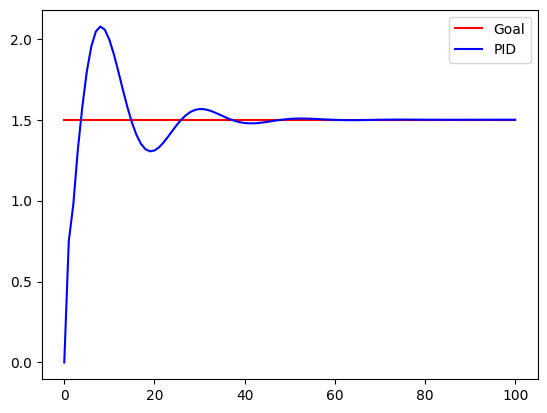

In [1]:
from matplotlib import pyplot as plt

#Ein kleiner Simulator
goal = 1.5
current = 0

p = 0.2
i = 0.1
d = 0.2

integral  = 0
previous_error = 0

time_line = [current]

for j in range(100):
    error = goal-current

    integral += error
    derivative = error - previous_error

    output = p*error + i*integral + d*derivative

    current += output
    previous_error = error
    time_line.append(current)


plt.plot([goal]*len(time_line), label="Goal", color="red")
plt.plot(time_line, label="PID",color="blue")
plt.legend()
plt.show()

### Klassen und Objekte

Um den vorherigen Fehler und das Integral über mehrere Methoden aufrufe hinweg verfolgen zu können brauchen wir eine sogenannte Klasse. 

Eine Klasse ist wie ein Bauplan. Sie beschreibt, welche Eigenschaften und Funktionen ein Objekt haben soll.
Ein Objekt ist dann ein konkretes Beispiel aus diesem Bauplan.
`Auto` ist die Klasse, `mein_auto` ist ein Objekt. `farbe` ist ein Attribut und `hupen()` ist eine Methode.
Ganz ähnlich arbeitet auch der Roboter: Er ist ein Objekt mit Eigenschaften wie `camera_image` und Methoden wie `start()` oder `forward()`.

In [4]:
class Auto:
    def __init__(self, farbe):
        self.farbe = farbe

    def hupen(self):
        print("Tutut!")

    def print_farbe(self):
        print(f"Meine Farbe ist {self.farbe}")

mein_auto = Auto("rot")
print(mein_auto.farbe)  # rot
mein_auto.hupen()       # Tutut!
mein_auto.print_farbe()  # Meine Farbe ist rot

rot
Tutut!
Meine Farbe ist rot


Der Forteil einer Klasse, ist dass sie Eigenschaften hat, die wir in den Methoden verwenden können. Die Eigenschaften sind an Objecte gebunden. Wenn wir ein zweites Object der Klasse erstellen kann dieses andere Eigenschaften haben. In der klasse greifen wir auf diese Eigenschaften zu indem wir ```self``` verwenden

In [5]:
anderes_auto = Auto("blau")
print(anderes_auto.farbe)  # blau
anderes_auto.hupen()       # Tutut!
anderes_auto.print_farbe()  # Meine Farbe ist blau

blau
Tutut!
Meine Farbe ist blau


### PID Regler für den Roboter
Jetzt könnt ihr euren eigenen PID regler schreiben. Euer PID-Regler bekommt einen Fehler zwischen -1 und 1 und soll daraus eine Geschwindigkeit v und eine Drehung omega berechnen. Dabei sollte das integral und der vorherige Fehler Eigenschaften der klasse sein

In [ ]:
class PIDController:
    def __init__(self):
        pass

    def pid_controller(self, error):

        v = 0
        omega = 0
        return v, omega

Wir benutzen den von euch geschriebenen PID regler nun um den Roboter zu steuern. Dafür überschreiben wir die PID-Methode des Roboters mit eurer eignen

In [ ]:
from Robot.robot import Robot

# ein roboter object erstellen
robot = Robot()

robot.pid_controller = PIDController().pid_controller
robot.start()